# Day 4 - Clean and See
What is associated with higher insurance charges, and how sure are we?


In [1]:
import pandas as pd
df_raw = pd.read_csv("../data/raw/insurance.csv")
df = df_raw.copy()

In [2]:
print( "  Shape: \n",df.shape,
       "\n\n  Head: \n", df.head(),
       "\n\n  Data Types: \n", df.dtypes,
       "\n\n  Empty Cells; \n", df.isna().sum(),
       "\n\n  Duplicated rows \n", df.duplicated().sum() )


  Shape: 
 (1338, 7) 

  Head: 
    age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520 

  Data Types: 
 age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object 

  Empty Cells; 
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64 

  Duplicated rows 
 1


## Findings
- 1338 rows, 7 columns
- Data types: age and children are int, bmi and charges are float; sex, smoker and region are text, so they need encoding before modelling
- No empty cells
- 1 duplicated row;
  - All 7 columns match, including charges to the cent, so it's most likely double entry
  - This will be removed because having a duplicate will shift the mean
  - And a drop from 1338 to 1337 entries does not cost much
  - Also, if the duplicate is split between train and test sets, the test accuracy will not be representative

In [3]:
print("Before:", df.shape)
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("After:", df.shape)
print("Duplicates now:", df.duplicated().sum())

Before: (1338, 7)
Duplicates: 1
After: (1337, 7)
Duplicates now: 0


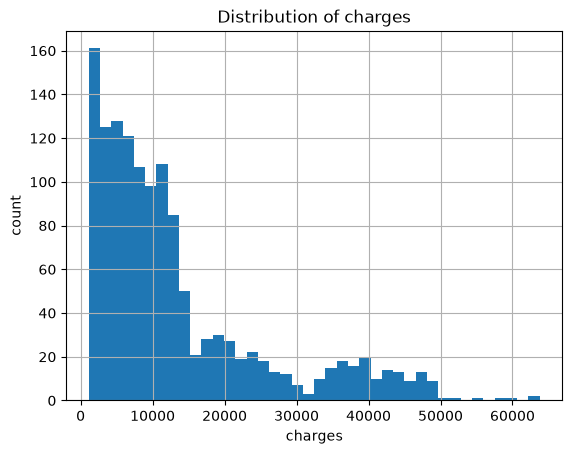

count     1337.000000
mean     13279.121487
std      12110.359656
min       1121.873900
25%       4746.344000
50%       9386.161300
75%      16657.717450
max      63770.428010
Name: charges, dtype: float64


In [4]:
import matplotlib.pyplot as plt

df["charges"].hist(bins=40)
plt.title("Distribution of charges")
plt.xlabel("charges")
plt.ylabel("count")
plt.show()

print(df["charges"].describe())

- The data is right-skewed.
- The mean is larger than the median
- This means mode data is in the lower range (below the mean)

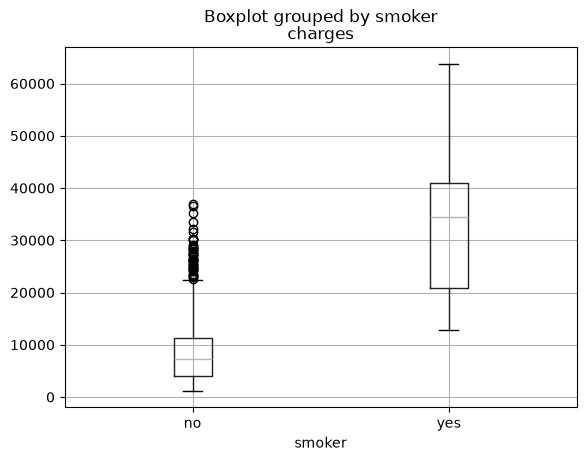

In [5]:
df.boxplot(column="charges", by="smoker")
plt.show()

- The smokers that pay the least still pay more than three-quarters of non-smokers
- Smoking is a strong correlator to charges

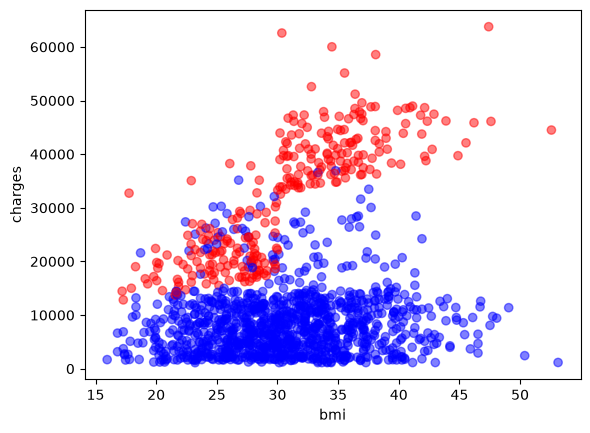

In [6]:
colors = df["smoker"].map({"yes": "red", "no": "blue"})
plt.scatter(df["bmi"], df["charges"], c=colors, alpha=0.5)
plt.xlabel("bmi"); plt.ylabel("charges")
plt.show()

- BMI matters a lot for smokers and little for non-smokers